In [2]:
import re
import os

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from datasets import ClassLabel, load_dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainerCallback,
    TrainingArguments,
)

c:\git\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
data_dir = "pan25-generative-ai-detection-task2-train"

train_path = os.path.join(data_dir, "train.jsonl")
test_path = os.path.join(data_dir, "dev.jsonl")

model_id = "FacebookAI/roberta-base"
label_order = [0, 1, 2, 3, 4, 5]
num_labels = len(label_order)
output_dir = "roberta_pan_task2_runs"

max_length = 512
batch_size = 8
num_epochs = 5
learning_rate = 2e-5
weight_decay = 0.01
# fraction of total training steps for LR warmup (Transformers 5.x uses warmup_steps, not warmup_ratio)
warmup_ratio = 0.1
val_fraction = 0.05
random_seed = 1
early_stopping_patience = 2

# set true for pipeline smoke tests; false for full gpu training
debug_subset = True
debug_train_rows = 50
debug_val_rows = 50
debug_test_rows = 50

In [4]:
raw = load_dataset(
    "json",
    data_files={"train": train_path, "test": test_path},
)

print(raw)
print("train rows:", raw["train"].num_rows)
print("test rows:", raw["test"].num_rows)

DatasetDict({
    train: Dataset({
        features: ['text', 'language', 'label', 'source_dataset', 'model', 'label_text'],
        num_rows: 288918
    })
    test: Dataset({
        features: ['text', 'language', 'label', 'source_dataset', 'model', 'label_text'],
        num_rows: 72661
    })
})
train rows: 288918
test rows: 72661


In [5]:
def clean_text(text):
    text = str(text)
    text = text.replace("_SEP_", " ")
    text = text.replace("\n", " ")
    text = text.replace("\r", " ")
    text = re.sub(r"\s+", " ", text)
    text = text.strip()
    return text


def add_clean_text(batch):
    batch["text_clean"] = [clean_text(t) for t in batch["text"]]
    return batch


raw = raw.map(add_clean_text, batched=True, desc="clean text")


def cast_label(batch):
    batch["label"] = [int(x) for x in batch["label"]]
    return batch


raw = raw.map(cast_label, batched=True)

# required for stratified train_test_split in datasets
label_feature = ClassLabel(num_classes=num_labels, names=[str(i) for i in label_order])
raw = raw.cast_column("label", label_feature)

In [6]:
train_val = raw["train"].train_test_split(
    test_size=val_fraction,
    seed=random_seed,
    stratify_by_column="label",
)

ds_train = train_val["train"]
# datasets train_test_split names the holdout split "test", not "validation"
ds_val = train_val["test"]
ds_test = raw["test"]

if debug_subset:
    ds_train = ds_train.shuffle(seed=random_seed).select(range(min(debug_train_rows, len(ds_train))))
    ds_val = ds_val.shuffle(seed=random_seed).select(range(min(debug_val_rows, len(ds_val))))
    ds_test = ds_test.shuffle(seed=random_seed).select(range(min(debug_test_rows, len(ds_test))))

print("ds_train:", len(ds_train), "ds_val:", len(ds_val), "ds_test:", len(ds_test))

ds_train: 50 ds_val: 50 ds_test: 50


In [7]:
tokenizer = AutoTokenizer.from_pretrained(model_id)


def tokenize_batch(batch):
    return tokenizer(
        batch["text_clean"],
        truncation=True,
        max_length=max_length,
        padding=False,
    )


cols_to_drop = [c for c in ds_train.column_names if c not in ("label",)]
ds_train = ds_train.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)
ds_val = ds_val.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)
ds_test = ds_test.map(tokenize_batch, batched=True, remove_columns=cols_to_drop)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map: 100%|██████████| 50/50 [00:00<00:00, 461.06 examples/s]


In [17]:
id2label = {i: str(i) for i in label_order}
label2id = {str(i): i for i in label_order}

model = AutoModelForSequenceClassification.from_pretrained(
    model_id,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro", labels=label_order, zero_division=0),
    }


use_cuda = torch.cuda.is_available()
# Modified by Cursor: warmup_ratio -> warmup_steps (removed in transformers 5.x).
_steps_per_epoch = max(1, (len(ds_train) + batch_size - 1) // batch_size)
_num_training_steps = _steps_per_epoch * num_epochs
warmup_steps = int(warmup_ratio * _num_training_steps)

training_args = TrainingArguments(
    output_dir=output_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none",
    seed=random_seed,
    use_cpu=not use_cuda,
)

class LogEpochMetricsCallback(TrainerCallback):
    # Modified by Cursor: one log_history row per epoch for learning-curve plots.
    def __init__(self):
        self.trainer = None

    def on_epoch_end(self, args, state, control, **kwargs):
        if self.trainer is None:
            return control
        train_metrics = self.trainer.evaluate(
            self.trainer.train_dataset,
            metric_key_prefix="train",
        )
        val_metrics = self.trainer.evaluate(
            self.trainer.eval_dataset,
            metric_key_prefix="eval",
        )
        state.log_history.append(
            {
                "epoch": float(state.epoch),
                "loss": train_metrics.get("train_loss"),
                "train_accuracy": train_metrics.get("train_accuracy"),
                "eval_loss": val_metrics.get("eval_loss"),
                "eval_accuracy": val_metrics.get("eval_accuracy"),
                "eval_f1_macro": val_metrics.get("eval_f1_macro"),
            }
        )
        return control


log_epoch_metrics_callback = LogEpochMetricsCallback()

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=early_stopping_patience),
        log_epoch_metrics_callback,
    ],
)
log_epoch_metrics_callback.trainer = trainer

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 635.53it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [18]:
train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.728330,0.260000,0.068783
2,1.697079,1.671302,0.260000,0.068783
3,1.589957,1.620161,0.320000,0.129002
4,1.438629,1.617535,0.320000,0.126023
5,1.297971,1.615197,0.320000,0.126023


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.15it/s]
[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.46it/s]
[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.05it/s]
[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.48it/s]
[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.83it/s]


TrainOutput(global_step=35, training_loss=1.5420017787388394, metrics={'train_runtime': 1039.2721, 'train_samples_per_second': 0.241, 'train_steps_per_second': 0.034, 'total_flos': 64229154169752.0, 'train_loss': 1.5420017787388394, 'epoch': 5.0})


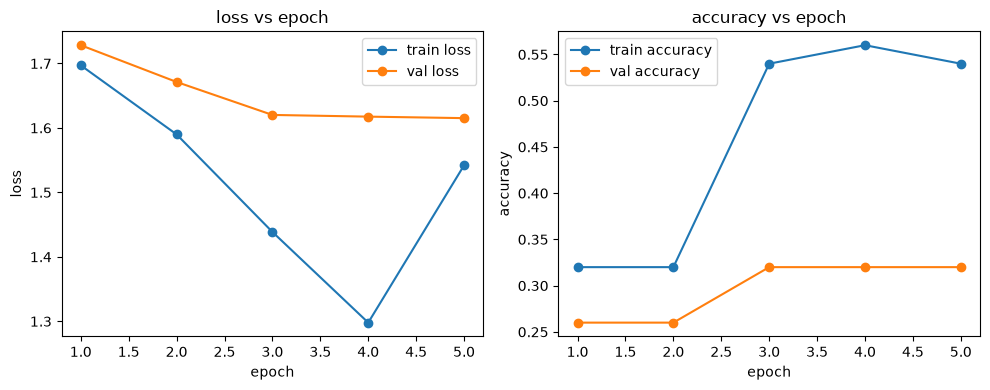

In [19]:
# Modified by Cursor: aggregate per-epoch metrics (HF may omit eval_* from log_history).
epoch_to_train_loss = {}
epoch_to_val_loss = {}
epoch_to_train_acc = {}
epoch_to_val_acc = {}
for entry in trainer.state.log_history:
    if "epoch" not in entry:
        continue
    epoch_num = int(round(float(entry["epoch"])))
    if "eval_loss" in entry:
        epoch_to_val_loss[epoch_num] = entry["eval_loss"]
        if "eval_accuracy" in entry:
            epoch_to_val_acc[epoch_num] = entry["eval_accuracy"]
    if "train_loss" in entry:
        epoch_to_train_loss[epoch_num] = entry["train_loss"]
    elif "loss" in entry and "eval_loss" not in entry:
        epoch_to_train_loss[epoch_num] = entry["loss"]
    if "train_accuracy" in entry:
        epoch_to_train_acc[epoch_num] = entry["train_accuracy"]

epochs_eval = sorted(
    set(epoch_to_train_loss)
    | set(epoch_to_val_loss)
    | set(epoch_to_train_acc)
    | set(epoch_to_val_acc)
)
train_losses = [epoch_to_train_loss.get(epoch, np.nan) for epoch in epochs_eval]
eval_losses = [epoch_to_val_loss.get(epoch, np.nan) for epoch in epochs_eval]
train_accs = [epoch_to_train_acc.get(epoch, np.nan) for epoch in epochs_eval]
eval_accs = [epoch_to_val_acc.get(epoch, np.nan) for epoch in epochs_eval]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(epochs_eval, train_losses, marker="o", label="train loss")
axes[0].plot(epochs_eval, eval_losses, marker="o", label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("loss vs epoch")
axes[0].legend()

axes[1].plot(epochs_eval, train_accs, marker="o", label="train accuracy")
axes[1].plot(epochs_eval, eval_accs, marker="o", label="val accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].set_title("accuracy vs epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [20]:
predictions = trainer.predict(ds_test)
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

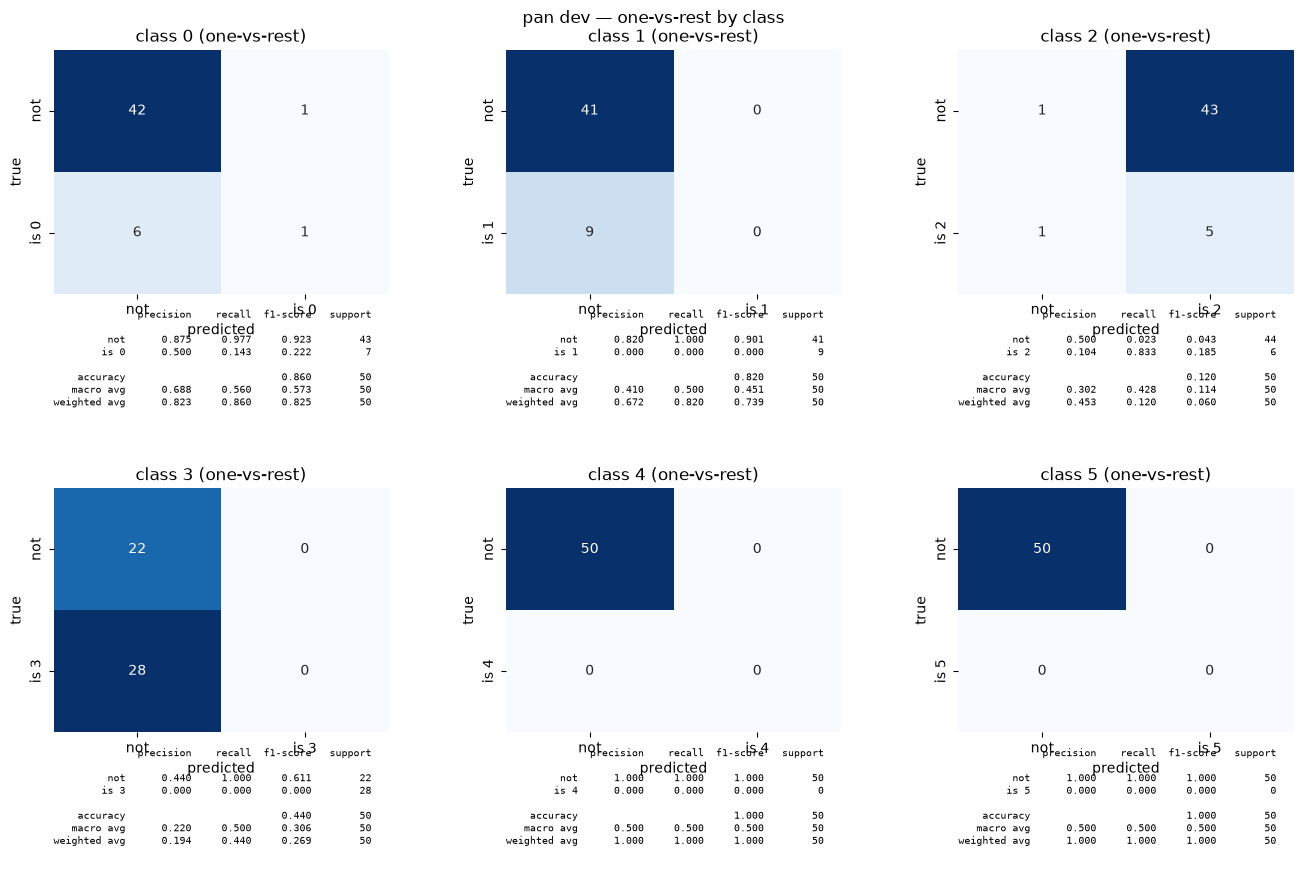

In [21]:
fig = plt.figure(figsize=(16, 10))
outer = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.12)

for block, labels_in_block in enumerate([label_order[:3], label_order[3:]]):
    inner = gridspec.GridSpecFromSubplotSpec(
        2,
        3,
        subplot_spec=outer[block],
        height_ratios=[2.2, 1.2],
        hspace=0.08,
        wspace=0.35,
    )

    for col, label in enumerate(labels_in_block):
        ax_cm = fig.add_subplot(inner[0, col])
        ax_report = fig.add_subplot(inner[1, col])

        y_true_bin = (y_true == label).astype(int)
        y_pred_bin = (y_pred == label).astype(int)
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            xticklabels=["not", f"is {label}"],
            yticklabels=["not", f"is {label}"],
            ax=ax_cm,
        )
        ax_cm.set_xlabel("predicted")
        ax_cm.set_ylabel("true")
        ax_cm.set_title(f"class {label} (one-vs-rest)")

        report_str = classification_report(
            y_true_bin,
            y_pred_bin,
            labels=[0, 1],
            target_names=["not", f"is {label}"],
            digits=3,
            zero_division=0,
        )
        ax_report.axis("off")
        ax_report.text(
            0.0,
            1.0,
            report_str,
            transform=ax_report.transAxes,
            va="top",
            ha="left",
            fontsize=7.5,
            family="monospace",
        )

plt.suptitle("pan dev — one-vs-rest by class", y=0.98)
fig.subplots_adjust(top=0.94)
plt.show()

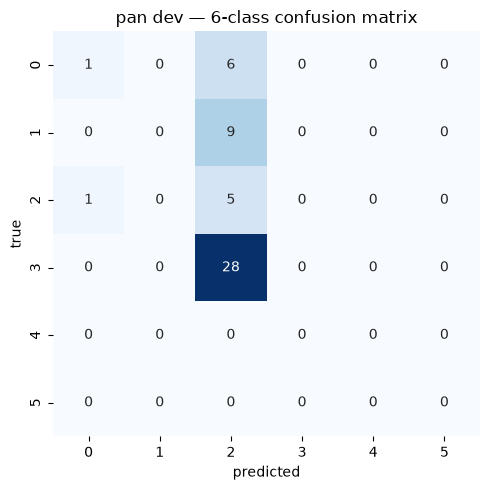

              precision    recall  f1-score   support

           0      0.500     0.143     0.222         7
           1      0.000     0.000     0.000         9
           2      0.104     0.833     0.185         6
           3      0.000     0.000     0.000        28
           4      0.000     0.000     0.000         0
           5      0.000     0.000     0.000         0

    accuracy                          0.120        50
   macro avg      0.101     0.163     0.068        50
weighted avg      0.083     0.120     0.053        50



In [22]:
cm_full = confusion_matrix(y_true, y_pred, labels=label_order)

fig, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(
    cm_full,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=label_order,
    yticklabels=label_order,
    ax=ax,
)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("pan dev — 6-class confusion matrix")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_true,
        y_pred,
        labels=label_order,
        digits=3,
        zero_division=0,
    )
)

In [14]:
# save_dir = "roberta_pan_task2_checkpoint"
# trainer.save_model(save_dir)
# tokenizer.save_pretrained(save_dir)